# EDA: логи HDFS, сводная тетрадь чекпойнта 2

Проект «Детектирование аномалий в данных распределенных облаков», куратор Дмитрий Качкин.
Команда: Артем Погосян, Степан Поляков, Аркадий Шевыров, Табриз Мусаев.

Разведочный анализ (EDA, exploratory data analysis) разделен по темам, как распределил куратор.
Эта тетрадь сводит части в одно место и закрывает обязательные пункты EDA для ML-трека:
описательные статистики, пропуски, ошибочные значения, выбросы, корреляции с таргетом и pairplot.

| Часть | Ответственный | Тетрадь |
| --- | --- | --- |
| Общий EDA: объем, структура лога, компоненты, узлы | Табриз Мусаев | [EDA Base.ipynb](EDA%20Base.ipynb) |
| Шаблоны событий, Drain3 | Аркадий Шевыров | [notebooks/Drain3/Drain3.ipynb](notebooks/Drain3/Drain3.ipynb) |
| Кластеры сессий | Степан Поляков | [notebooks/clustering/EDA_clustering.ipynb](notebooks/clustering/EDA_clustering.ipynb) |
| Временные ряды | Степан Поляков | [notebooks/time_series/EDA_time_series.ipynb](notebooks/time_series/EDA_time_series.ipynb) |
| Семантика: мешок слов и TF-IDF | Артем Погосян | [EDA_semantika.ipynb](EDA_semantika.ipynb) |
| Практическая ценность (pdf) | команда | [practical_value.pdf](practical_value.pdf) |

**Данные.** HDFS_v1 из loghub: 11 175 629 строк лога распределенной файловой системы Hadoop,
собранных за 38,7 часа на кластере из 200+ узлов. Строки сгруппированы в сессии по номеру блока
`blk_…`, каждая сессия размечена авторами набора как нормальная или аномальная.
Скачать: `python scripts/download_hdfs_v1.py` (кладет данные в `data/loghub/HDFS_v1`).
Тетрадь запускается из корня репозитория, пакеты из `pyproject.toml`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"норма": "#3B6FB6", "аномалия": "#C65353"}

DATA = Path("data/loghub/HDFS_v1/preprocessed")
EVENTS = [f"E{i}" for i in range(1, 30)]

## 1. Данные и их согласованность

В наборе три таблицы на уровне сессии:

* `Event_occurrence_matrix.csv`: сколько раз каждое из 29 событий (шаблонов строк E1…E29) встретилось в сессии,
  метка `Label` (`Success` или `Fail`) и код типа аномалии `Type`;
* `Event_traces.csv`: последовательность событий сессии, интервалы между соседними строками (`TimeInterval`, секунды)
  и длительность сессии (`Latency`, секунды);
* `anomaly_label.csv`: исходная разметка `Normal` или `Anomaly`.

Сначала проверяем, что таблицы описывают одни и те же сессии в одном порядке и метки в них не расходятся.

In [2]:
occ = pd.read_csv(DATA / "Event_occurrence_matrix.csv")
traces = pd.read_csv(DATA / "Event_traces.csv")
labels = pd.read_csv(DATA / "anomaly_label.csv")
templates = pd.read_csv(DATA / "HDFS.log_templates.csv")

for name, df in [("occurrence", occ), ("traces", traces), ("labels", labels)]:
    print(f"{name:<11} {df.shape[0]:>7} строк, {df.shape[1]:>2} столбцов")

same_order = (occ["BlockId"].to_numpy() == traces["BlockId"].to_numpy()).all()
merged = occ[["BlockId", "Label"]].merge(labels, on="BlockId", suffixes=("_matrix", "_file"))
print("порядок сессий в матрице и в трассах совпадает:", same_order)
print("сессий с меткой в обоих файлах:", len(merged))
pd.crosstab(merged["Label_matrix"], merged["Label_file"])

occurrence   575061 строк, 32 столбцов
traces       575061 строк,  6 столбцов
labels       575061 строк,  2 столбцов
порядок сессий в матрице и в трассах совпадает: True
сессий с меткой в обоих файлах: 575061


Label_file,Anomaly,Normal
Label_matrix,,
Fail,16838,0
Success,0,558223


Таблицы согласованы: 575 061 сессия, порядок совпадает, метки `Fail` и `Anomaly` совпадают один к одному.
Дальше таргет `y = 1` для аномалии.

Шаблоны событий, по которым построена матрица:

In [3]:
templates

,EventId,EventTemplate
0,E1,[*]Adding an already existing block[*]
1,E2,[*]Verification succeeded for[*]
2,E3,[*]Served block[*]to[*]
3,E4,[*]Got exception while serving[*]to[*]
4,E5,[*]Receiving block[*]src:[*]dest:[*]
5,E6,[*]Received block[*]src:[*]dest:[*]of size[*]
6,E7,[*]writeBlock[*]received exception[*]
7,E8,[*]PacketResponder[*]for block[*]Interrupted[*]
8,E9,[*]Received block[*]of size[*]from[*]
9,E10,[*]PacketResponder[*]Exception[*]


## 2. Признаки сессии и описательные статистики

Помимо 29 счетчиков событий соберем пять сводных признаков сессии:

| признак | что значит |
| --- | --- |
| `seq_len` | число строк лога в сессии |
| `n_unique` | число различных событий в сессии |
| `duration_s` | длительность сессии, секунды |
| `max_gap_s` | самая длинная пауза между соседними строками, секунды |
| `n_exc` | число строк с исключениями и ошибками (E4, E7, E8, E10, E12, E14, E17, E20, E29) |

In [4]:
y = (occ["Label"] == "Fail").astype(int)
cls = y.map({0: "норма", 1: "аномалия"})
gaps = traces["TimeInterval"].map(lambda s: np.array(json.loads(s)))
EXC = ["E4", "E7", "E8", "E10", "E12", "E14", "E17", "E20", "E29"]

feat = pd.DataFrame({
    "seq_len": occ[EVENTS].sum(axis=1),
    "n_unique": (occ[EVENTS] > 0).sum(axis=1),
    "duration_s": traces["Latency"],
    "max_gap_s": gaps.map(lambda a: a.max() if len(a) else 0.0),
    "n_exc": occ[EXC].sum(axis=1),
})
SUMMARY = list(feat.columns)

feat.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
seq_len,575061.0,19.4,5.2,2.0,19.0,19.0,20.0,298.0
n_unique,575061.0,7.3,1.6,2.0,7.0,7.0,8.0,20.0
duration_s,575061.0,16789.5,17887.0,0.0,1144.0,7229.0,33680.0,54025.0
max_gap_s,575061.0,11996.5,12445.8,0.0,965.0,6848.0,22037.0,53611.0
n_exc,575061.0,0.6,1.6,0.0,0.0,0.0,0.0,41.0


In [5]:
# те же статистики отдельно по классам: медиана и 90-й перцентиль
by_class = feat.groupby(cls).quantile([0.5, 0.9]).unstack().T
by_class.index.names = ["признак", "квантиль"]
by_class.round(1)

Label                аномалия    норма
признак    квантиль                   
seq_len    0.5           20.0     19.0
           0.9           30.0     25.0
n_unique   0.5            8.0      7.0
           0.9           12.0      9.0
duration_s 0.5         4920.5   7303.0
           0.9        48810.9  48138.0
max_gap_s  0.5         3483.5   6946.0
           0.9        27256.3  28551.0
n_exc      0.5            1.0      0.0
           0.9            2.0      2.0

In [6]:
# счетчики событий: в какой доле сессий событие есть и сколько его в среднем
ev = pd.DataFrame({
    "доля сессий с событием, %": (occ[EVENTS] > 0).mean() * 100,
    "среднее": occ[EVENTS].mean(),
    "максимум": occ[EVENTS].max(),
    "std": occ[EVENTS].std(),
})
ev.round(3)

,"доля сессий с событием, %",среднее,максимум,std
E1,0.001,0.000,2,0.006
E2,14.382,0.209,4,0.581
E3,23.899,0.746,203,2.517
E4,22.484,0.619,41,1.605
E5,100.000,2.997,13,0.221
E6,0.912,0.012,10,0.147
E7,0.574,0.006,5,0.081
E8,0.008,0.000,2,0.010
E9,98.921,2.968,3,0.310
E10,0.012,0.000,3,0.019


**Вывод.** Нормальная сессия очень однотипна: медиана 19 строк и 7 различных событий,
межквартильный размах `seq_len` всего от 19 до 20 строк. Длительность, наоборот, разбросана
от 0 до 15 часов (медиана около 2 часов). Аномальные сессии в медиане чуть длиннее по числу строк
(20 против 19), но короче по времени (около 1,4 часа против 2), и в них есть строки с исключениями.
Событие E22 (выделение блока, `allocateBlock`) есть ровно один раз в каждой сессии, то есть это константа.

## 3. Пропуски

Ищем пустые значения во всех трех таблицах.

In [7]:
na = pd.DataFrame({
    "occurrence": occ.isna().sum(),
    "traces": traces.isna().sum().reindex(occ.columns),
}).fillna(0).astype(int)
display(na[na.sum(axis=1) > 0])
print("пропусков в anomaly_label.csv:", int(labels.isna().sum().sum()))
pd.crosstab(occ["Label"], occ["Type"].isna().map({True: "Type пуст", False: "Type заполнен"}))

,occurrence,traces
Type,558223,558223


пропусков в anomaly_label.csv: 0


Type,Type заполнен,Type пуст
Label,,
Fail,16838,0
Success,0,558223


**Вывод.** Пустые значения есть только в столбце `Type`, и это не пропуски: код типа заполнен ровно у всех
16 838 аномалий и пуст у всех 558 223 нормальных сессий. В счетчиках, трассах и метках пропусков нет,
заполнять нечего. `Type` в признаки модели не берем, он повторяет таргет.

## 4. Ошибочные значения

Проверяем то, что должно выполняться по смыслу данных:

1. номер блока уникален, счетчики неотрицательны, длительность неотрицательна;
2. в трассе интервалов на один меньше, чем строк, а их сумма равна длительности сессии;
3. сумма счетчиков равна длине последовательности событий;
4. каждый блок выделен ровно один раз (E22 = 1), то есть сессия записана с начала, а не обрезана.

In [8]:
seq_from_trace = traces["Features"].str.count("E")
checks = {
    "повторов BlockId": int(occ["BlockId"].duplicated().sum()),
    "отрицательных счетчиков": int((occ[EVENTS] < 0).sum().sum()),
    "отрицательной длительности": int((feat["duration_s"] < 0).sum()),
    "интервалов не на 1 меньше строк": int((gaps.map(len) != feat["seq_len"] - 1).sum()),
    "сумма интервалов != длительности": int((~np.isclose(gaps.map(np.sum), feat["duration_s"])).sum()),
    "сумма счетчиков != длине трассы": int((seq_from_trace != feat["seq_len"]).sum()),
    "сессий с E22 != 1": int((occ["E22"] != 1).sum()),
}
pd.Series(checks, name="нарушений").to_frame()

,нарушений
повторов BlockId,0
отрицательных счетчиков,0
отрицательной длительности,0
интервалов не на 1 меньше строк,0
сумма интервалов != длительности,0
сумма счетчиков != длине трассы,0
сессий с E22 != 1,0


In [9]:
zero = feat["duration_s"] == 0
print(f"сессий нулевой длительности: {zero.sum()} ({zero.mean():.2%}), из них аномалий {y[zero].mean():.1%}")
print("различных векторов счетчиков:", occ[EVENTS].drop_duplicates().shape[0])
print("из них встречаются у нормальных:", occ.loc[y == 0, EVENTS].drop_duplicates().shape[0])
print("типы аномалий среди сессий нулевой длительности:")
print(occ.loc[zero & (y == 1), "Type"].astype(int).value_counts().head(3).to_string())

сессий нулевой длительности: 2683 (0.47%), из них аномалий 97.1%
различных векторов счетчиков: 589
из них встречаются у нормальных: 212
типы аномалий среди сессий нулевой длительности:
Type
3    2605
7       1


**Вывод.** Ошибочных значений нет: все семь проверок дают ноль нарушений. Сессии нулевой длительности
(все строки в одну секунду) тоже не ошибка, время в логе пишется с точностью до секунды. Но это сильный
сигнал: таких сессий 2 683, и 97,1% из них аномалии, почти все типа 3 (2 605 из 2 950 сессий этого типа).
Блок выделен и сразу брошен, штатного завершения записи нет. Совпадающие строки
матрицы тоже не ошибка: 575 061 сессия укладывается всего в 589 различных векторов счетчиков, потому что
система делает одно и то же. Для оценки моделей это важно: случайное разбиение на train и test почти
наверняка положит одинаковые векторы в обе части, поэтому разбивать будем по времени.

## 5. Выбросы

Классическое правило IQR (выброс, если значение выше третьего квартиля больше чем на полтора
межквартильных размаха) здесь проверим на всех пяти сводных признаках.

In [10]:
rows = []
for c in SUMMARY:
    q1, q3 = feat[c].quantile([0.25, 0.75])
    hi = q3 + 1.5 * (q3 - q1)
    out = feat[c] > hi
    rows.append({"признак": c, "Q1": q1, "Q3": q3, "граница": hi,
                 "выбросов, %": out.mean() * 100,
                 "аномалий среди выбросов, %": y[out].mean() * 100 if out.any() else np.nan})
pd.DataFrame(rows).set_index("признак").round(2)

,Q1,Q3,граница,"выбросов, %","аномалий среди выбросов, %"
признак,,,,,
seq_len,19.0,20.0,21.5,23.78,4.42
n_unique,7.0,8.0,9.5,10.30,9.33
duration_s,1144.0,33680.0,82484.0,0.00,NaN
max_gap_s,965.0,22037.0,53645.0,0.00,NaN
n_exc,0.0,0.0,0.0,23.78,7.78


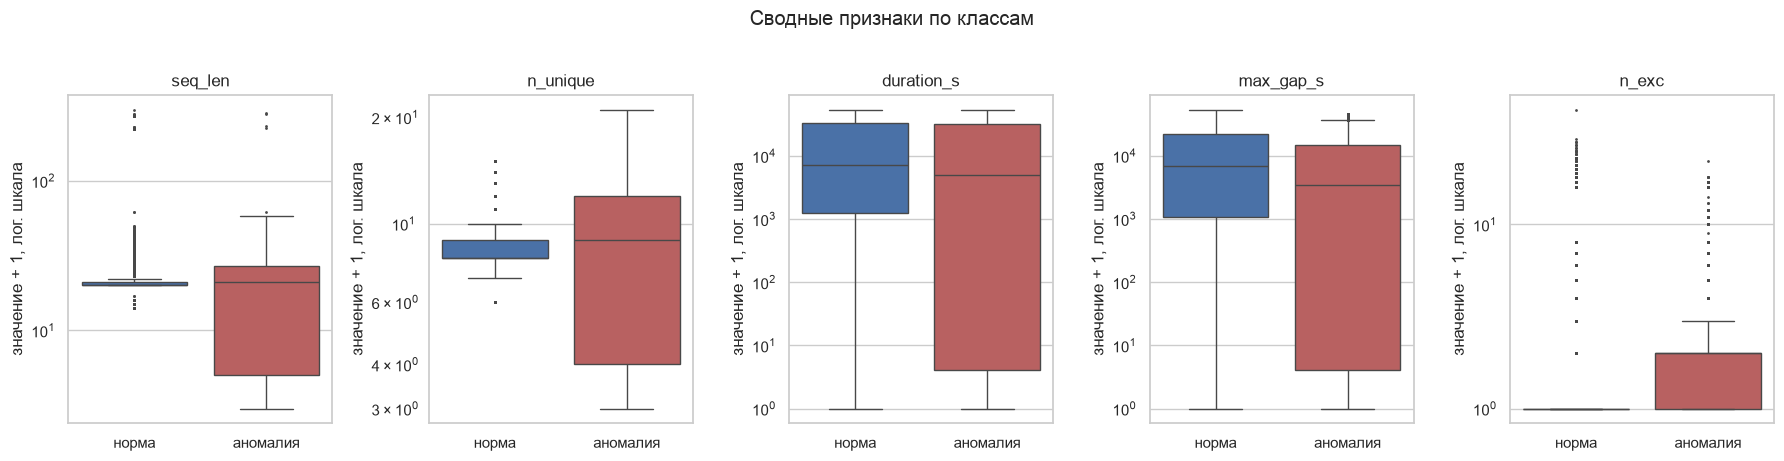

In [11]:
fig, axes = plt.subplots(1, len(SUMMARY), figsize=(18, 4.5))
for ax, c in zip(axes, SUMMARY):
    sns.boxplot(x=cls, y=feat[c] + 1, ax=ax, hue=cls, palette=PALETTE, legend=False,
                fliersize=1, order=["норма", "аномалия"])
    ax.set_yscale("log")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("значение + 1, лог. шкала")
plt.suptitle("Сводные признаки по классам", y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# хвост распределения длины: самые длинные 1% и 0,1% сессий
for q in [0.99, 0.999]:
    t = feat["seq_len"].quantile(q)
    tail = feat["seq_len"] > t
    print(f"seq_len > {t:.0f} (выше {q:.1%}): {tail.sum():>5} сессий, аномалий {y[tail].mean():.1%}")
short = feat["seq_len"] <= 10
print(f"seq_len <= 10: {short.sum():>5} сессий, аномалий {y[short].mean():.1%}")
print(f"доля аномалий во всем наборе: {y.mean():.2%}")

seq_len > 33 (выше 99.0%):  5451 сессий, аномалий 19.4%
seq_len > 41 (выше 99.9%):   343 сессий, аномалий 76.4%
seq_len <= 10:  6191 сессий, аномалий 100.0%
доля аномалий во всем наборе: 2.93%


**Вывод.** Правило IQR к этим данным неприменимо. У `seq_len` межквартильный размах равен одной строке,
поэтому «выбросом» оказывается почти четверть сессий, а у `n_exc` и третий квартиль равен нулю,
так что выбросом считается любая сессия с исключением. У длительности и паузы выбросов по IQR нет.
При этом хвосты информативны: среди 1% самых длинных сессий (больше 33 строк) аномалий 19,4%,
среди 0,1% самых длинных (больше 41 строки) 76,4% при 2,93% в среднем. Нижний хвост еще чище:
все 6 191 сессия длиной до 10 строк аномальные. Выбросы не удаляем: в задаче поиска аномалий редкие сессии
и есть предмет поиска. Для моделей признаки с тяжелым хвостом логарифмируем.

## 6. Таргет

Баланс классов и коды типов аномалий из разметки (расшифровки кодов в наборе нет,
смысл крупных типов восстановлен по словам в [EDA_semantika.ipynb](EDA_semantika.ipynb)).

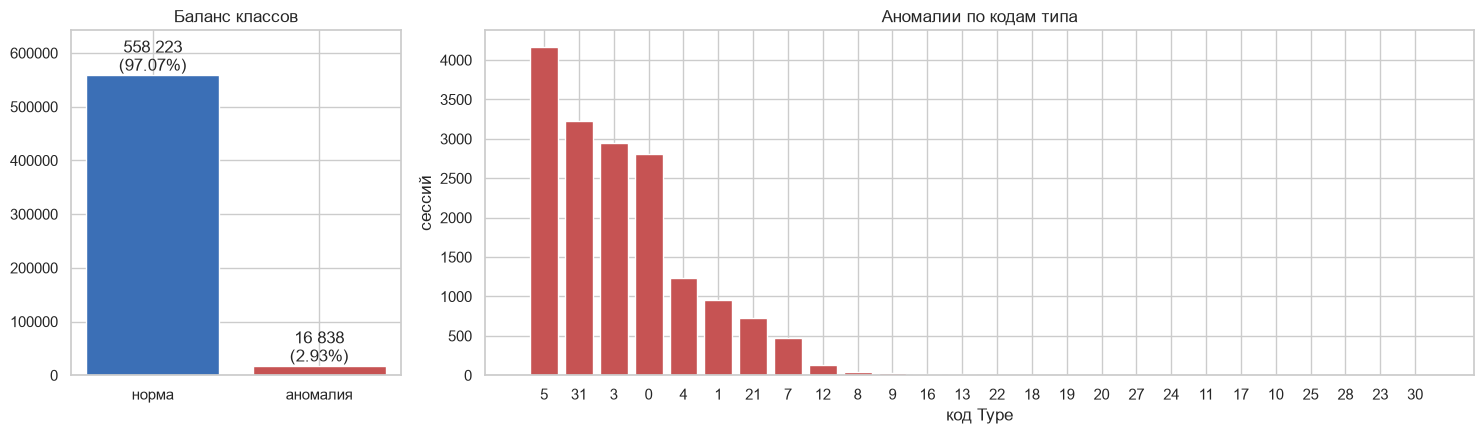

доля четырех крупнейших типов: 78.1%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 3]})
counts = cls.value_counts().reindex(["норма", "аномалия"])
axes[0].bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(cls):.2%})".replace(",", " "), ha="center", va="bottom")
axes[0].set_title("Баланс классов")
axes[0].set_ylim(0, counts.max() * 1.15)

types = occ.loc[y == 1, "Type"].astype(int).value_counts()
axes[1].bar(types.index.astype(str), types.values, color=PALETTE["аномалия"])
axes[1].set_title("Аномалии по кодам типа")
axes[1].set_xlabel("код Type")
axes[1].set_ylabel("сессий")
plt.tight_layout()
plt.show()

print("доля четырех крупнейших типов:", f"{types.head(4).sum() / types.sum():.1%}")

**Вывод.** Аномалий 2,93% (16 838 из 575 061): сильный дисбаланс. Accuracy (доля верных ответов) здесь
бесполезна, модель «все нормально» дает 97%. Оцениваем по recall, precision и PR AUC, порог выбираем
под целевой recall, как просил куратор. Кодов типа 26, но четыре крупнейших (5, 31, 3, 0)
покрывают 78,1% аномалий, остальные типы малочисленны.

## 7. Корреляции с таргетом

Для каждого признака считаем две меры связи с `y`:

* **точечно-бисериальную корреляцию** (коэффициент Пирсона между признаком и бинарным таргетом),
  она показывает линейную связь и ее знак;
* **ROC AUC признака** (вероятность того, что у случайной аномалии значение признака выше, чем у случайной нормы),
  она устойчива к тяжелым хвостам; 0,5 значит нет связи, меньше 0,5 значит у аномалий признак ниже.

E22 исключаем: это константа.

In [14]:
X = pd.concat([feat, occ[EVENTS].drop(columns="E22")], axis=1)
corr = pd.DataFrame({
    "corr": X.apply(lambda col: np.corrcoef(col, y)[0, 1]),
    "ROC AUC": X.apply(lambda col: roc_auc_score(y, col)),
    "среднее в норме": X[y == 0].mean(),
    "среднее в аномалиях": X[y == 1].mean(),
})
corr = corr.sort_values("corr", key=np.abs, ascending=False)
corr.round(3).head(15)

,corr,ROC AUC,среднее в норме,среднее в аномалиях
E9,-0.603,0.315,3.000,1.891
E11,-0.598,0.317,3.000,1.901
E20,0.526,0.652,0.000,0.316
E7,0.424,0.598,0.000,0.203
E18,0.312,0.602,0.005,0.265
E25,0.312,0.602,0.005,0.265
E16,0.310,0.601,0.005,0.261
E6,0.300,0.601,0.005,0.266
E28,0.261,0.537,0.000,0.076
E26,-0.255,0.453,3.009,2.391


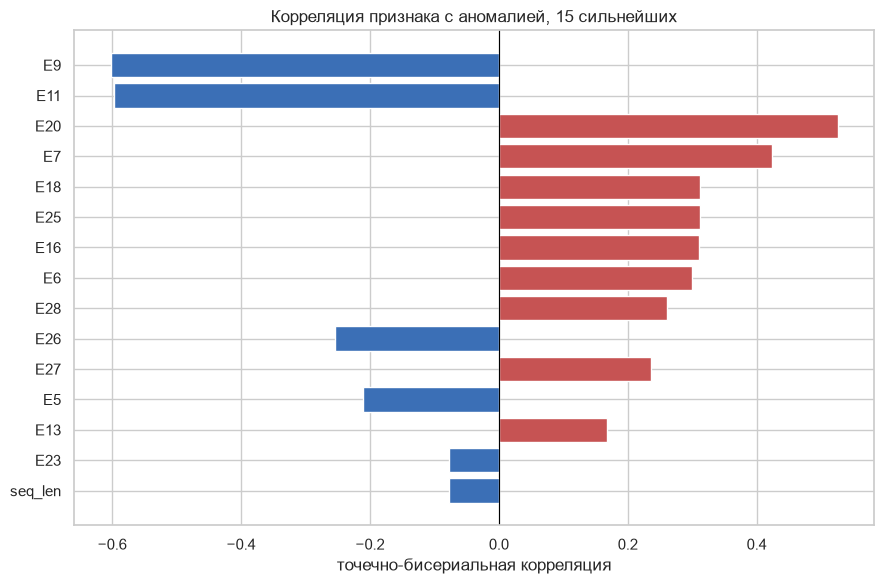

In [15]:
top = corr.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["corr"], color=np.where(top["corr"] > 0, PALETTE["аномалия"], PALETTE["норма"]))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Корреляция признака с аномалией, 15 сильнейших")
ax.set_xlabel("точечно-бисериальная корреляция")
plt.tight_layout()
plt.show()

In [16]:
present = occ[EVENTS] > 0
share = pd.DataFrame({
    "есть в норме, %": present[y == 0].mean() * 100,
    "есть в аномалиях, %": present[y == 1].mean() * 100,
}).join(templates.set_index("EventId")["EventTemplate"].str.replace("[*]", " ", regex=False).str.strip())
only_anom = share.index[(share["есть в норме, %"] == 0) & (share["есть в аномалиях, %"] > 0)]
print("событий, которые встречаются только в аномалиях:", len(only_anom))
print(f"аномалий хотя бы с одним таким событием: {present.loc[y == 1, only_anom].any(axis=1).mean():.1%}")
share.sort_values("есть в аномалиях, %", ascending=False).round(2).head(16)

событий, которые встречаются только в аномалиях: 12
аномалий хотя бы с одним таким событием: 22.8%


,"есть в норме, %","есть в аномалиях, %",EventTemplate
E5,100.00,100.00,Receiving block src: dest:
E22,100.00,100.00,BLOCK* NameSystem allocateBlock:
E11,100.00,63.29,PacketResponder for block terminating
E9,100.00,63.14,Received block of size from
E26,100.00,63.14,BLOCK* NameSystem addStoredBlock: blockMap updated: is added to size
E21,81.73,61.72,Deleting block file
E23,81.45,61.39,BLOCK* NameSystem delete: is added to invalidSet of
E20,0.04,30.44,Unexpected error trying to delete block BlockInfo not found in volumeMap
E3,23.97,21.54,Served block to
E18,0.32,20.74,Starting thread to transfer block to


Корреляции между самими признаками: если признаки дублируют друг друга, линейной модели
это мешает (мультиколлинеарность), а деревьям безразлично.

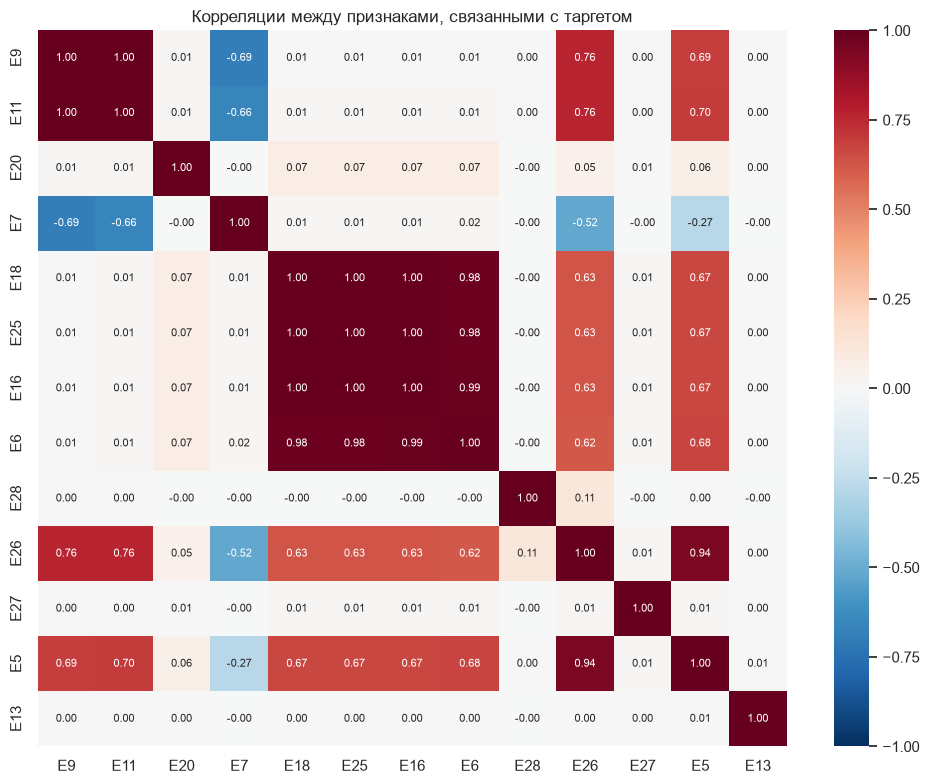

In [17]:
strong = corr.index[corr["corr"].abs() > 0.15]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X[strong].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Корреляции между признаками, связанными с таргетом")
plt.tight_layout()
plt.show()

**Вывод.** Сильнее всего с аномалией связано **отсутствие** штатных событий:
E9 (подтверждение приема блока) и E11 (завершение PacketResponder) есть в каждой нормальной сессии
и пропадают примерно в трети аномалий, корреляция около −0,6. Из положительных признаков сильнейшие
E20 (ошибка удаления блока, «BlockInfo not found») и E7 (исключение при записи): в норме их почти нет.
Двенадцать событий встречаются только в аномалиях, но вместе покрывают лишь 22,8% аномалий,
так что простого правила «есть редкое событие» мало. Линейная связь сводных признаков с таргетом слабая
(|corr| < 0,1), но по ROC AUC они не пустые: `n_exc` 0,66, `duration_s` 0,39 (у аномалий короче).
Аномалию выдает прежде всего состав сессии, размер и время дополняют его.

Признаки дублируют друг друга группами: E9 и E11 (корреляция 1,00), E6, E16, E18, E25 (передача и
репликация блока, 0,98 и выше), E5 и E26 (0,94). События идут цепочкой, поэтому для линейных моделей
группы стоит сворачивать в один признак или регуляризовать.

## 8. Pairplot

Попарные распределения сводных признаков и двух сильнейших счетчиков. Для читаемости берем
стратифицированную выборку: 3 000 нормальных и 3 000 аномальных сессий (в выборке классы уравнены,
поэтому доли на графике не равны долям в данных). Признаки логарифмированы: `log1p(x) = ln(1 + x)`.

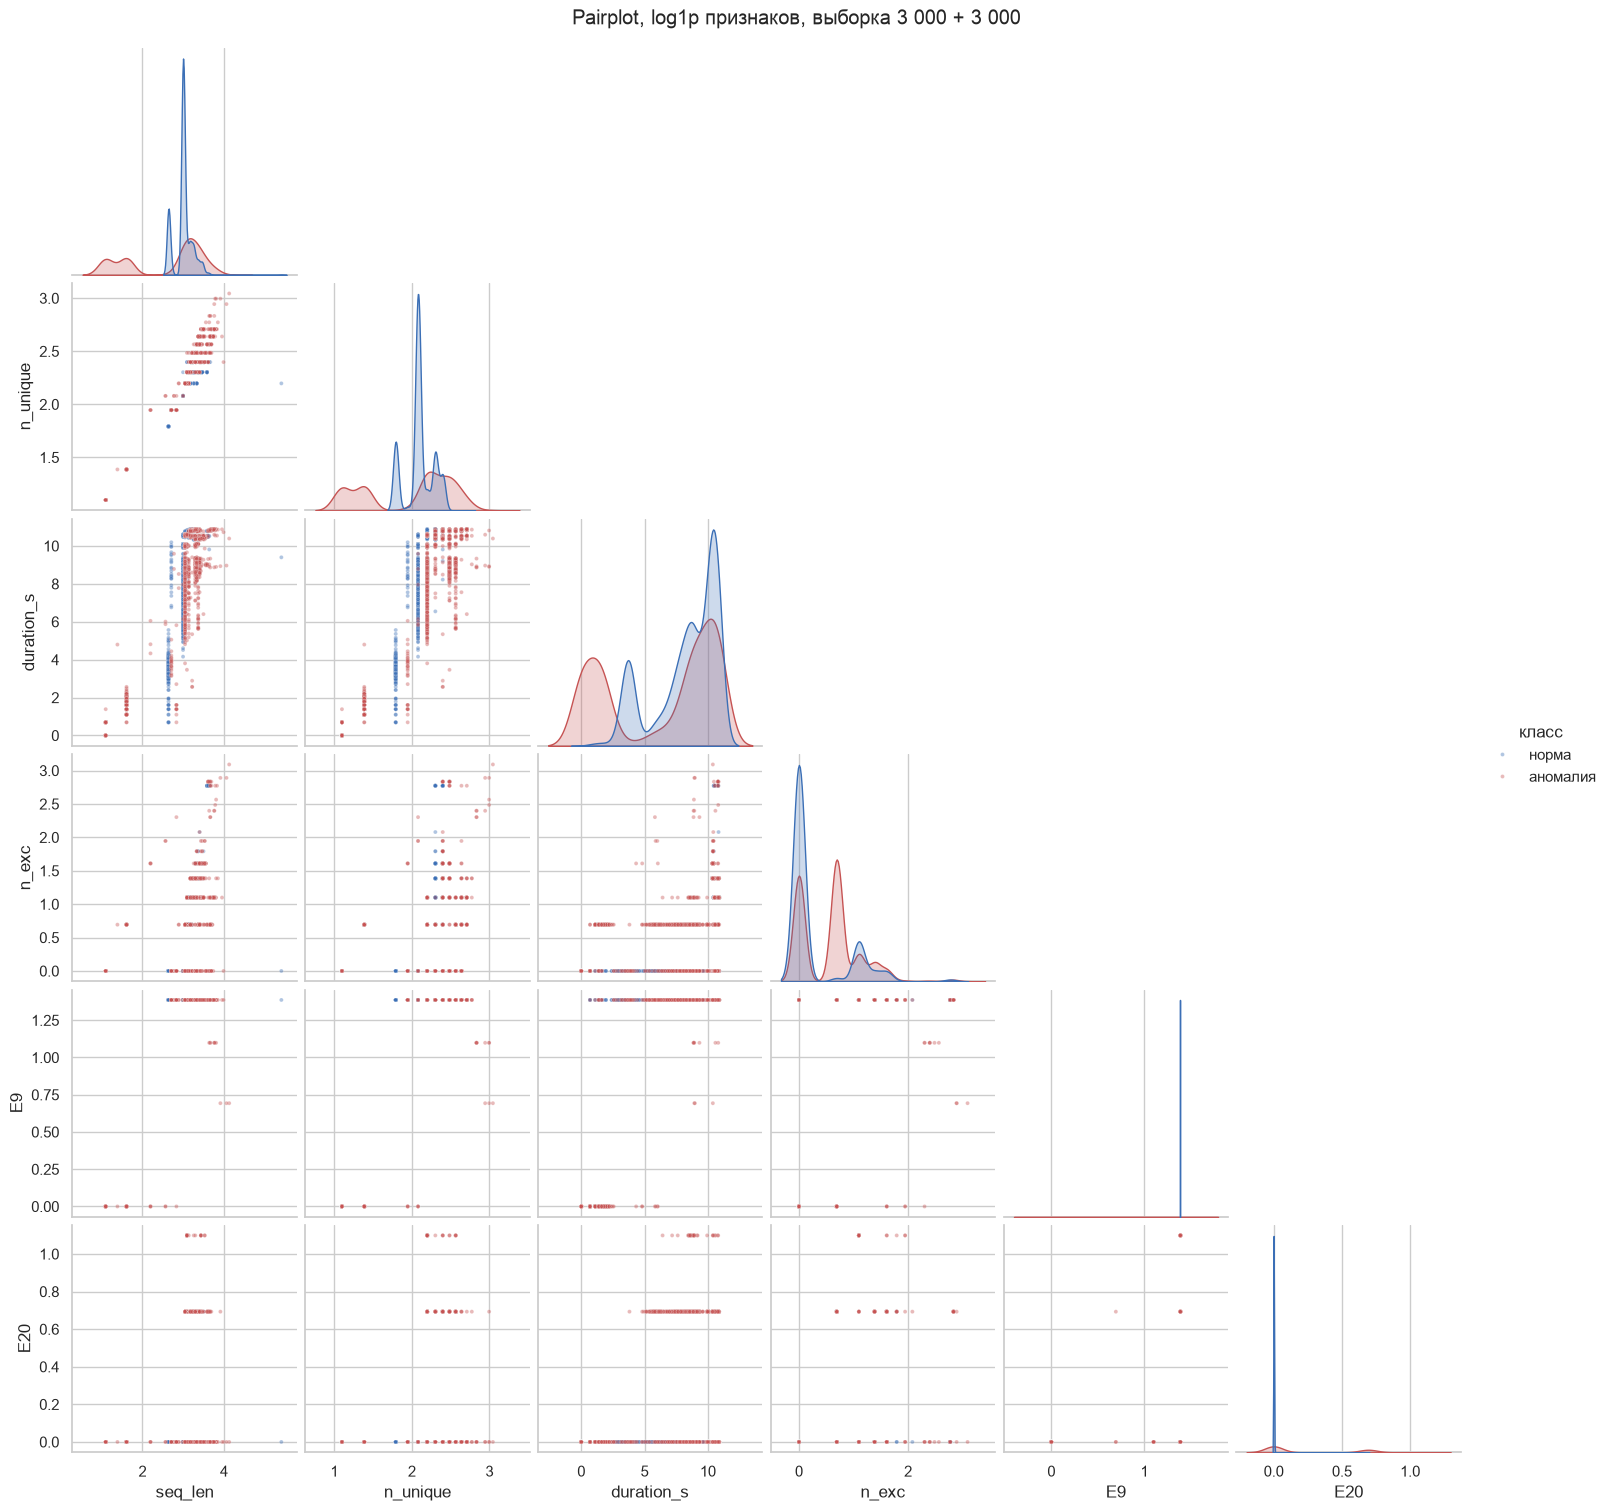

In [18]:
rng = np.random.default_rng(42)
idx = np.concatenate([rng.choice(np.flatnonzero(y == k), 3000, replace=False) for k in (0, 1)])
pp = np.log1p(X.iloc[idx][["seq_len", "n_unique", "duration_s", "n_exc", "E9", "E20"]])
pp["класс"] = cls.iloc[idx].to_numpy()
g = sns.pairplot(pp, hue="класс", palette=PALETTE, corner=True, plot_kws={"s": 8, "alpha": 0.4},
                 diag_kind="kde", diag_kws={"common_norm": False, "warn_singular": False})
g.figure.suptitle("Pairplot, log1p признаков, выборка 3 000 + 3 000", y=1.01)
plt.show()

**Вывод.** В основной массе облака классов перекрываются, но видны чистые зоны аномалий.
Короткие сессии почти нулевой длительности (слева внизу на графиках `seq_len` и `duration_s`): все 6 191 сессия
короче 11 строк аномальные, это 36,8% всех аномалий. Сессии с E9, равным нулю, тоже только аномальные,
а с E20 больше нуля аномальны на 95,9%. Сессии с исключениями (`n_exc` больше нуля) встречаются в обоих
классах из-за штатного E4.
Признаки длины и времени дополняют состав сессии, но не заменяют его.

## 9. Итоги частей команды

**Общий EDA (Табриз, [EDA Base.ipynb](EDA%20Base.ipynb)).** Лог разобран целиком: 11 175 629 строк,
пустых строк нет, 575 061 сессия, аномалий 2,93%. Строки уровня WARN дает в основном компонент `BlockReceiver`,
штатную нагрузку (INFO) несут `DataXceiver` и `FSNamesystem`. Аномалии распределены по узлам кластера
неравномерно, часть узлов собирает заметно больше сбоев.

**Шаблоны (Аркадий, [Drain3.ipynb](notebooks/Drain3/Drain3.ipynb)).** Drain3 (алгоритм разбора логов на шаблоны)
с масками номера блока и адреса и порогом сходства 0,6 выделил на всем логе 47 шаблонов против 29 в эталонной
разметке loghub. Число шаблонов растет с объемом: 12 на 1 000 строк, 20 на 100 000 строк, 47 на всем логе.
Скрипт [Drain3.py](notebooks/Drain3/Drain3.py) пишет разобранные строки и шаблоны в `data/processed/drain3/`.

**Кластеры (Степан, [EDA_clustering.ipynb](notebooks/clustering/EDA_clustering.ipynb)).** На TF-IDF слов шаблонов
PCA оставил 7 компонент (96,9% дисперсии). KMeans без меток лучше всего делит сессии на 10 кластеров
(силуэт 0,87); три кластера состоят в основном из аномалий и собирают 14 231 из 16 838 аномалий.
HDBSCAN оставил большую часть сессий вне плотных групп и аномалий в «своих» группах собрал меньше.

**Временные ряды (Степан, [EDA_time_series.ipynb](notebooks/time_series/EDA_time_series.ipynb)).**
Наблюдение длится 38,7 часа. Число строк в минуту: медиана около 1 600, пик 210 778 строк (11.11.2008, 04:43).
Автокорреляция на сдвиге в минуту 0,40 и быстро падает. Ряд нестационарен: в последней четверти периода
среднее в 3,2 раза выше, чем в первой. Сезонность на таком коротком отрезке не подтверждается.

**Семантика (Артем, [EDA_semantika.ipynb](EDA_semantika.ipynb)).** 29 шаблонов дают словарь из 64 слов.
Аномалию выдают как тревожные слова (write, not, unexpected), так и пропажа слов штатного завершения
(terminating, stored). Слово exception само по себе почти бесполезно: precision 4,9% из-за штатного E4.
Sublinear TF-IDF (с логарифмом счетчика) и расстояние до средней нормальной сессии дают без обучения
ROC AUC 0,997. 1,9% аномалий по набору слов совпадают с нормой: для них нужны порядок и время.

## 10. Общие выводы и что берем в чекпойнт 3

1. **Данные чистые.** Пропусков и ошибочных значений нет, три таблицы согласованы, разметка полная.
   Чистить нечего; E22 (константа) и `Type` (повторяет таргет) в признаки не идут.
2. **Сильный дисбаланс, 2,93% аномалий.** Метрики: recall, precision, PR AUC; порог под целевой recall.
3. **Сессии почти одинаковые.** 575 061 сессия дает 589 различных векторов счетчиков. Разбиение
   на train и test только по времени, иначе одинаковые векторы попадут в обе части и качество завысится.
4. **Главный сигнал в составе сессии.** Отсутствие штатных событий (E9, E11) и появление ошибочных (E20, E7)
   связаны с аномалией сильнее, чем длина или длительность; брошенные сессии нулевой длительности
   почти всегда аномальны. Правило IQR для выбросов не подходит, редкие сессии оставляем.
5. **Базовые представления для моделей:** счетчики событий (логарифмированные), sublinear TF-IDF слов,
   сводные признаки длины и времени. Дублирующие группы (E9 и E11, E6, E16, E18, E25) для линейных моделей сворачиваем.
6. **Предел «мешка» признаков около 98% recall:** часть аномалий неотличима по составу, для нее
   нужны порядок событий и время: модель следующего события на n-граммах в чекпойнте 3, нейросети в чекпойнте 6.

План на чекпойнт 3 по [README](README.md): базовые решения (правило запрещенных событий и PCA), Isolation Forest,
кластеризация и подход через временные ряды. Обучение только на нормальных сессиях, разбиение по времени,
порог под целевой recall; обучение с учителем по замечанию куратора не в приоритете.